# π0, step by step 🤖
### A vision-language model that learns to *flow* Gaussian noise into robot action chunks

**Model:** `Pi0Policy` (`src/Halo_VLA/pi_family/pi0.py`) · **paper:** K. Black et al., *π0: A Vision-Language-Action Flow Model for
General Robot Control*, 2024 ([arXiv:2410.24164](https://arxiv.org/abs/2410.24164)) · **reference code:** [openpi](https://github.com/Physical-Intelligence/openpi)

π0 answers one question: *how do you turn a pre-trained VLM into a robot policy that outputs smooth, high-frequency, multimodal continuous actions?*
Its answer has three ingredients, and this notebook builds and tests each one:

| ingredient | what it is | step |
|---|---|---|
| **action chunks** | predict the next `H` actions at once (π0: H = 50 at 50 Hz = 1 s) | 0 |
| **mixture of transformers** | the VLM weights read images + text; a smaller *action expert* reads state + noisy actions; they meet only inside attention | 1-3 |
| **flow matching** | the action expert predicts a *velocity* that moves noise toward the action chunk; 10 Euler steps at run time | 4-6 |

Then we train it on a toy robot world, watch it denoise, run it in closed loop, and check that flow matching handles a **multimodal**
task that plain regression gets wrong.

| | published π0 | this notebook |
|---|---|---|
| backbone | PaliGemma 3B (SigLIP + Gemma 2B, width 2048, 18 layers) | linear patch embedding + 2 layers, width 64 |
| VLM pre-training | web-scale image-text data | 1500 steps of toy VQA (Step 7) |
| action expert | 300M, width 1024, 18 layers | width 48, 2 layers |
| chunk | H = 50, up to 18-dim actions | H = 16, 2-dim actions |
| denoising | 10 Euler steps | 10 Euler steps |

> Runs on a laptop CPU in about 6 minutes (VQA pre-training, one robot training and two shorter ones). Sibling notebooks: `pi05_step_by_step.ipynb`, `pi07_step_by_step.ipynb`.

## Step 0: Setup and the toy world

The **point world** (`pi_family.toy`) is a 32×32 RGB image with 2-3 coloured squares and a white robot dot.

* **observation** `o_t` = image `I_t` + robot state `q_t` (its xy position) + language instruction `ℓ`
* **action** `a_t` = a 2D motion command, normalised so `|a| ≈ 1` is one full step (0.05 of the world width)
* **action chunk** `A_t = [a_t, …, a_{t+H-1}]`: π0 predicts all of them at once, then executes the first `Ĥ` (here 8) and re-plans.

Two tasks: `"go to red | green | blue"` (one correct target, the main model) and, in Step 11, `"go to any"` (**two** correct targets; the
demonstrator picks one at random).

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import pi_kit
pi_kit.setup_paths()
from pi_kit import plots, diagrams as dg

from pi_family import Pi0Config, Pi0Policy, PiTrainer, FlowMatching, make_attention_mask, split_prefix_suffix_mask
from pi_family.pretraining import VQAPretrainer
from pi_family.flow_matching import sinusoidal_time_embedding
from pi_family import EpisodeMetadata
from pi_family.toy import PointWorld, DemoGenerator, ChunkDataset, ClosedLoopEvaluator, make_scenarios, collate

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
print("torch", torch.__version__)

torch 2.13.0


4000 demonstrations, mean length 11.5 steps


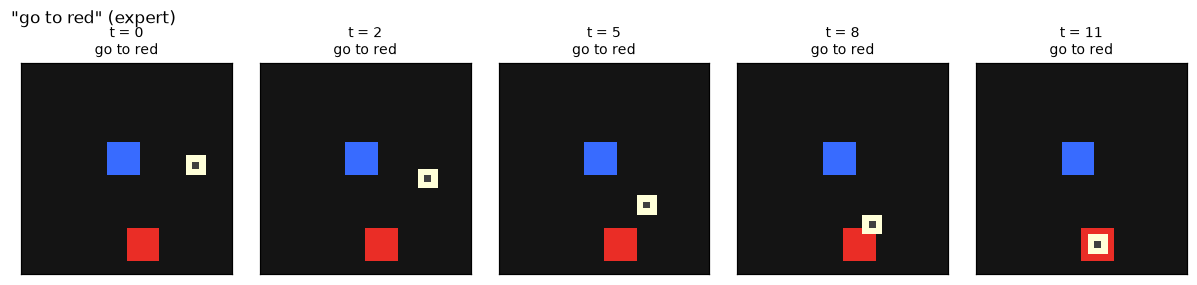

images (6, 3, 32, 32)  state (6, 2)  actions (6, 16, 2) = (B, H, action_dim)


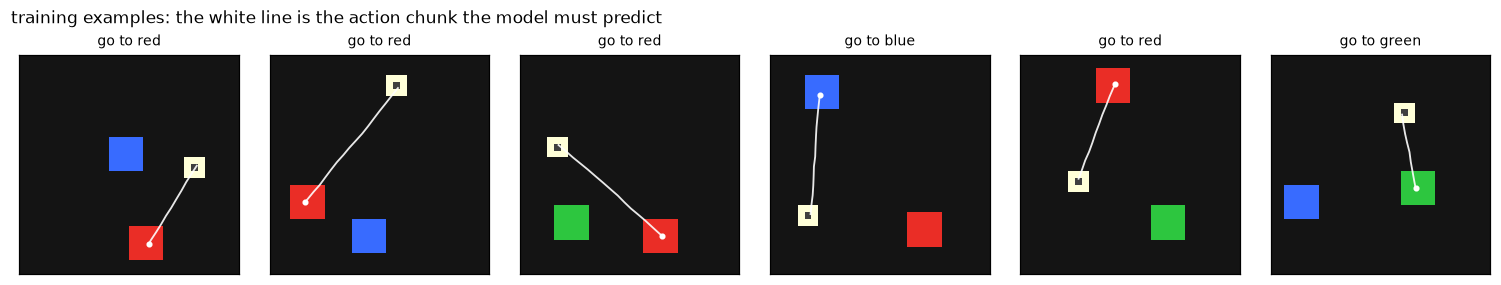

In [2]:
world = PointWorld()                       # 32x32 images, max_step 0.05, success radius 0.05
gen = DemoGenerator(world)
episodes = gen.dataset(["reach"], 4000, np.random.default_rng(0))     # scripted expert demonstrations
config = Pi0Config()
data = ChunkDataset(episodes, world, config.chunk_size)
print(f"{len(episodes)} demonstrations, mean length {np.mean([e.active_steps for e in episodes]):.1f} steps")

plots.show_episode(data, episodes[0])
rng = np.random.default_rng(1)
batch = collate([data.example(ep, int(rng.integers(0, 4)), rng) for ep in episodes[:6]])      # early in each episode
print("images", tuple(batch.images.shape), " state", tuple(batch.state.shape), " actions", tuple(batch.actions.shape), "= (B, H, action_dim)")
plots.show_batch(batch, title="training examples: the white line is the action chunk the model must predict")

### 🖼️ Diagram: the π family, and π0's architecture
π0 is the base every later model keeps. The figure below it is the whole model: blue = VLM weights, red = action-expert weights.

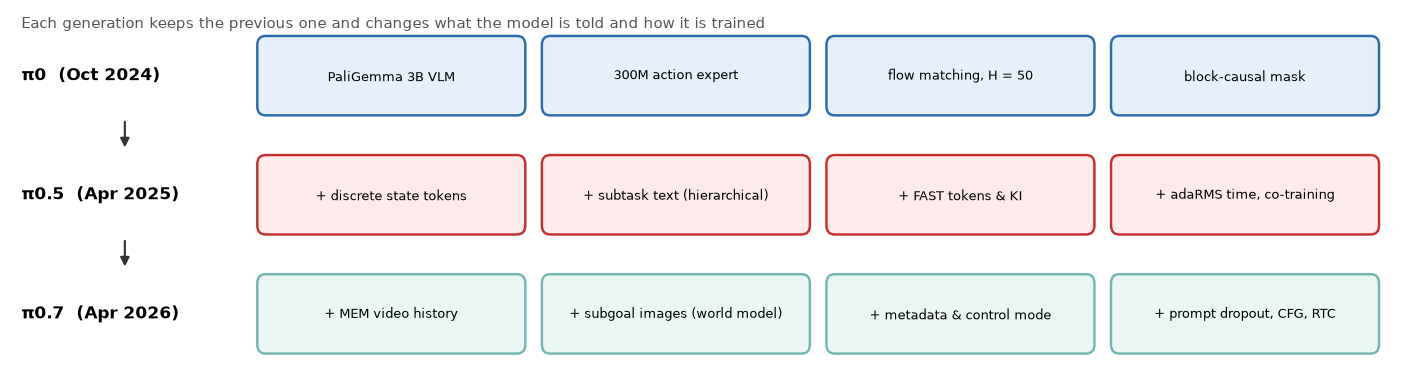

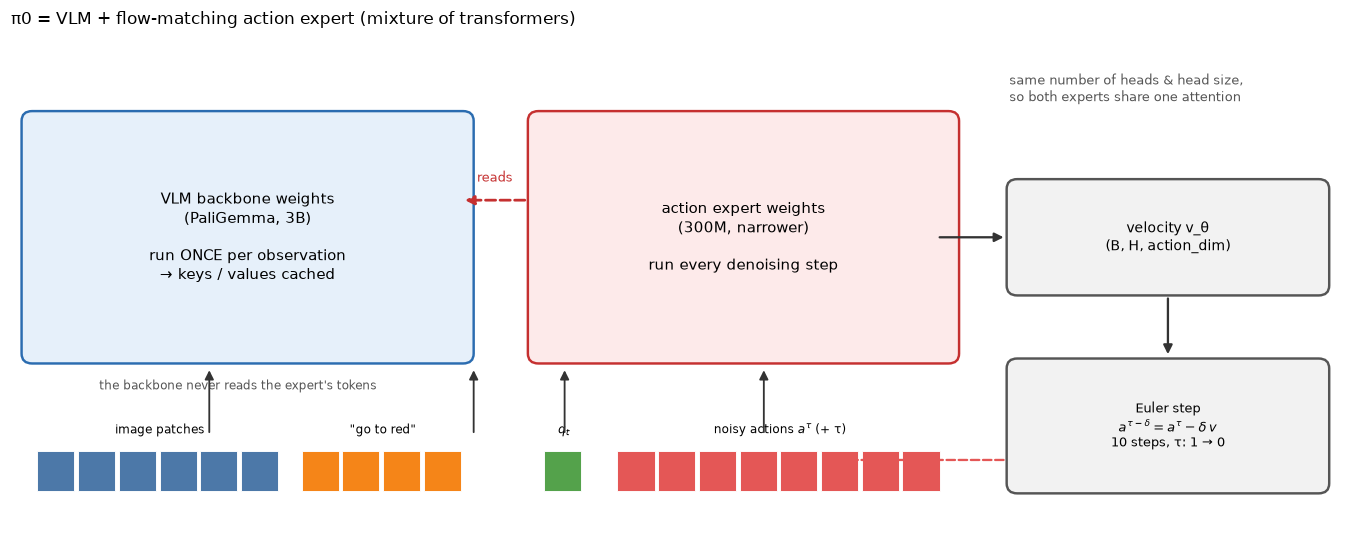

In [3]:
dg.fig_family_overview()
dg.fig_pi0_architecture()

## Step 1: Everything becomes a token

π0 writes the whole input as one sequence:

```
[ image patches ][ <bos> go to red ]   [ q_t ]   [ a^τ_1 … a^τ_H ]
└──── prefix: VLM weights ─────────┘   └──── suffix: action expert ────┘
```

* **image** → patch tokens (here 16 patches of 8×8 pixels; PaliGemma: 256 SigLIP tokens per 224² image)
* **text** → word tokens from the same vocabulary the VLM was trained on
* **state** `q_t` → *one* token, a linear projection (π0 is the only generation that does it this way)
* **noisy actions** → one token per action in the chunk, each fused with the flow time τ (Step 5)

prefix embeddings: (6, 20, 64) = (B, image patches + words, width)
suffix embeddings: (6, 17, 48) = (B, 1 state + H actions, expert_width)
segments: [('image', 0, 16), ('text', 16, 20)]


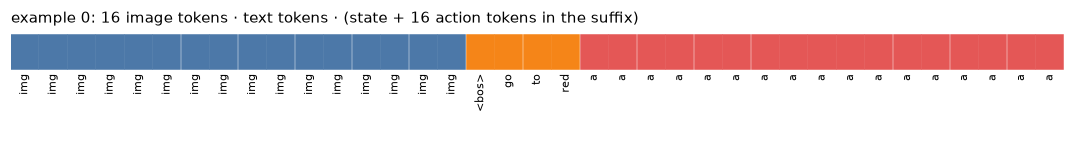

In [4]:
model = Pi0Policy(config)
prefix = model.build_prefix(batch, train=False)
noisy, tau = torch.randn(batch.size, config.chunk_size, 2), torch.full((batch.size, config.chunk_size), 0.7)
suffix = model.build_suffix(batch, noisy, tau)
print("prefix embeddings:", tuple(prefix.embeds.shape), "= (B, image patches + words, width)")
print("suffix embeddings:", tuple(suffix.embeds.shape), "= (B, 1 state + H actions, expert_width)")
print("segments:", prefix.segments)
plots.plot_token_layout(prefix, suffix_len=1 + config.chunk_size, vocab=model.vocab,
                        title='example 0: 16 image tokens · text tokens · (state + 16 action tokens in the suffix)')

## Step 2: The block-causal attention mask

Each token carries one bit `ar` ("starts a new block"). With `c = cumsum(ar)`, token *i* may attend token *j* iff `c[j] ≤ c[i]`.
So tokens inside a block see each other (bidirectional), and a block sees every block to its **left**, never to its right.

π0 uses three blocks: **[images + text] → [state] → [actions]**. Why this shape?

1. the prefix never sees robot tokens, so it stays close to what the pre-trained VLM computes (it is "insulated" from the new, strange inputs);
2. the prefix does not depend on the noise, so its keys/values can be **cached** across the 10 denoising steps (Step 6);
3. the state is its own block: it does not see the noisy actions either, so it too is the same at every denoising step;
4. action tokens see each other: the chunk is generated **jointly**, not one action at a time.

Toy example first: `ar = [1, 0, 0, 1, 1, 0]` is a 3-token block, then a 1-token block, then a 2-token block.

In [5]:
ar = torch.tensor([[1, 0, 0, 1, 1, 0]], dtype=torch.bool)
m = make_attention_mask(ar, torch.ones_like(ar))
print(m[0].int())

tensor([[1, 1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)


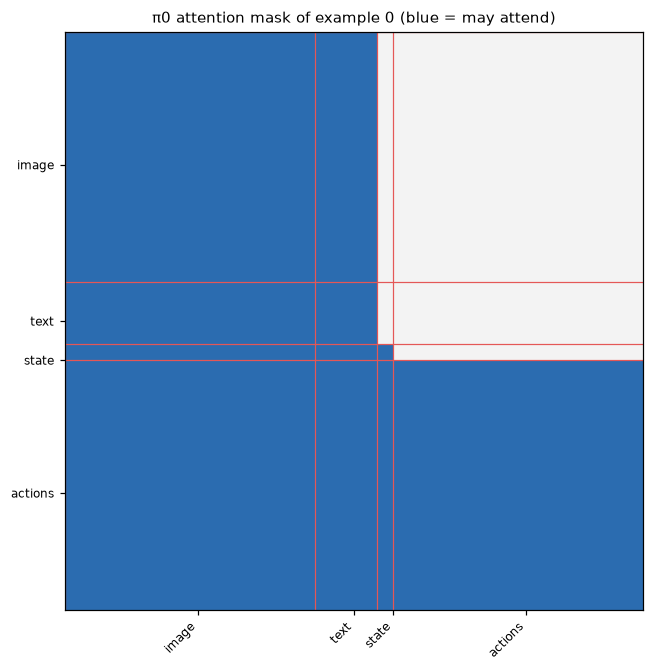

prefix queries never attend suffix keys: asserted inside split_prefix_suffix_mask ✓
state query attends actions? False   actions attend state? True


In [6]:
prefix_mask, suffix_mask = split_prefix_suffix_mask(prefix.ar, prefix.valid, prefix.action_visible, suffix.ar)
plots.plot_attention_mask(prefix_mask, suffix_mask, prefix, suffix_labels=[("state", 1), ("actions", config.chunk_size)],
                          title="π0 attention mask of example 0 (blue = may attend)")
lp = prefix.length
print("prefix queries never attend suffix keys: asserted inside split_prefix_suffix_mask ✓")
print("state query attends actions?", bool(suffix_mask[0, 0, lp + 1:].any()), "  actions attend state?", bool(suffix_mask[0, 1:, lp].all()))

## Step 3: Two experts, one attention

A **mixture of transformers** layer has *two* copies of every weight matrix (QKV, output, MLP, norms). Prefix tokens use the backbone
copy, suffix tokens use the action-expert copy. Inside attention all queries, keys and values are concatenated, so information flows
between them exactly as the mask allows. The experts may have different widths (here 64 vs 48; π0: 2048 vs 1024) as long as the number of
heads and the head size match.

Because the prefix never attends the suffix, we can compute the whole thing in **two passes** - backbone stack first (cache its keys/values),
then the expert stack against the cache - and get *exactly* the same numbers as one joint pass. We check this against the
straightforward joint implementation (`MixtureOfTransformers.forward_joint`).

In [7]:
print({k: f"{v:,}" for k, v in model.parameter_counts().items()})
with torch.no_grad():
    hidden, cache = model.encode_prefix(prefix)                                  # pass 1: backbone only
    two_pass = model.velocity(batch, prefix, cache, noisy, tau)                  # pass 2: expert reads the cache
    pos = model.prefix_position(torch.arange(prefix.length))[None]
    _, h_joint = model.transformer.forward_joint(prefix.embeds + pos, suffix.embeds, prefix_mask, suffix_mask)
    joint = model.action_out(h_joint[:, suffix.action_start:])
print("cached keys per layer:", tuple(cache.keys[0].shape), "= (B, heads, prefix length, head_dim)")
print(f"max |two-pass - joint| = {(two_pass - joint).abs().max():.2e}   (float32 round-off)")

{'total': '177,442', 'vision': '21,568', 'backbone': '82,240', 'action_expert': '52,416'}
cached keys per layer: (6, 4, 20, 16) = (B, heads, prefix length, head_dim)
max |two-pass - joint| = 1.86e-09   (float32 round-off)


## Step 4: Flow matching, the objective

For a demonstrated chunk `a` and Gaussian noise `ε`, define the straight line (openpi convention, τ = 1 is noise):

$$x_\tau = \tau\,\varepsilon + (1-\tau)\,a, \qquad u = \frac{dx_\tau}{d\tau} = \varepsilon - a$$

The action expert learns the velocity: $\;\mathcal{L} = \mathbb{E}_{a,\varepsilon,\tau}\,\big\|v_\theta(x_\tau, \tau \mid o) - (\varepsilon - a)\big\|^2$.

At run time we start from fresh noise at τ = 1 and integrate `dx/dτ = v_θ` back to τ = 0. Because many `(ε, a)` pairs cross the same `x_τ`,
the network learns their *average* direction, which is a proper **transport map from noise to the whole action distribution**: if the
demonstrations contain two different behaviours, different noise samples flow to different behaviours instead of being averaged (Step 11).

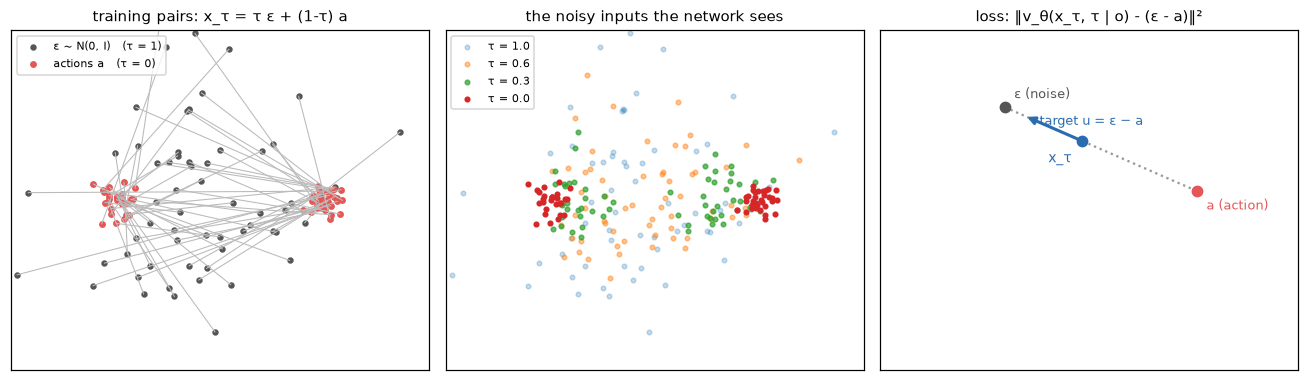

In [8]:
dg.fig_flow_matching_paths()

**Which τ to train on?** π0 samples τ from a shifted Beta(1.5, 1), which puts more weight on **high noise**. The argument: given a good
observation, the low-noise end is easy (the action is almost visible in `x_τ`); the hard, useful part is deciding *where to go* from noise.

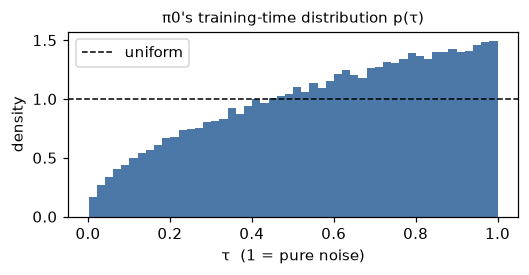

integrating the true velocity from ε recovers a: True


In [9]:
flow = FlowMatching()
t = flow.sample_time(100_000, generator=torch.Generator().manual_seed(0))
plt.figure(figsize=(5, 2.6)); plt.hist(t.numpy(), bins=50, density=True, color="#4c78a8")
plt.axhline(1, color="k", ls="--", lw=1, label="uniform"); plt.xlabel("τ  (1 = pure noise)"); plt.ylabel("density"); plt.legend()
plt.title("π0's training-time distribution p(τ)", fontsize=10); plt.tight_layout(); plt.show()

# a single (noise, action) pair: the path is straight, so Euler with the *true* velocity is exact for any step count
a, eps = torch.randn(1, 16, 2), torch.randn(1, 16, 2)
x0 = flow.integrate(lambda x, t: flow.target_velocity(a, eps), eps, num_steps=3)
print("integrating the true velocity from ε recovers a:", torch.allclose(x0, a, atol=1e-6))

## Step 5: Telling the action tokens what τ is

π0 embeds each noisy action together with τ by a small MLP: $\;W_3\,\mathrm{swish}\big(W_2\,[\,W_1 a^\tau_k,\ \phi(\tau)\,]\big)$, where $\phi$ is a
sinusoidal embedding with geometrically spaced periods (4·10⁻³ to 4). Short periods tell apart τ = 0.02 and τ = 0.03 at the end of sampling,
long periods give a smooth coarse signal. (π0.5 replaces this MLP by **adaptive RMSNorm**: see the next notebook.)

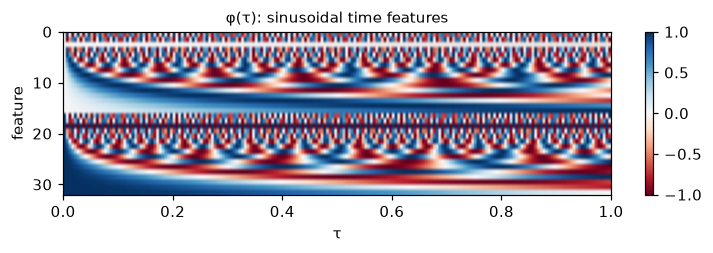

action-time MLP: ActionTimeMLP(
  (action_in): Linear(in_features=2, out_features=48, bias=True)
  (fuse): Linear(in_features=96, out_features=48, bias=True)
  (out): Linear(in_features=48, out_features=48, bias=True)
)


In [10]:
taus = torch.linspace(0, 1, 200)
emb = sinusoidal_time_embedding(taus, 32)
plt.figure(figsize=(7, 2.4)); plt.imshow(emb.T.numpy(), aspect="auto", cmap="RdBu", extent=[0, 1, 32, 0])
plt.xlabel("τ"); plt.ylabel("feature"); plt.title("φ(τ): sinusoidal time features", fontsize=10); plt.colorbar(); plt.tight_layout(); plt.show()
print("action-time MLP:", model.action_time)

## Step 6: Inference with a KV cache

Sampling = 10 Euler steps, each needs a velocity. The prefix (the expensive VLM part) is identical at every step, so π0 runs it **once** and
each step only runs the small action expert against the cached keys/values. We compare against a naive loop that re-runs the whole model
every step: same chunk, less work. (The π0 paper reports about 73 ms per chunk for the 3B model on an RTX 4090 this way.)

In [11]:
def naive_sample(model, batch, noise, steps=10):
    # re-encodes the prefix at every Euler step
    x = noise
    for k in range(steps):
        t = torch.full((batch.size,), 1 - k / steps)
        prefix = model.build_prefix(batch, train=False)
        _, cache = model.encode_prefix(prefix)
        x = x - (1 / steps) * model.velocity(batch, prefix, cache, x, t[:, None].expand(-1, config.chunk_size))
    return x

big = data.sample(64, np.random.default_rng(2))
noise = torch.randn(64, config.chunk_size, 2)
with torch.no_grad():
    t0 = time.perf_counter(); slow = naive_sample(model, big, noise); t_slow = time.perf_counter() - t0
    t0 = time.perf_counter(); fast = model.sample_actions(big, noise=noise); t_fast = time.perf_counter() - t0
print(f"naive {1000 * t_slow:.0f} ms, cached {1000 * t_fast:.0f} ms, max difference {(slow - fast).abs().max():.1e}")

naive 70 ms, cached 21 ms, max difference 0.0e+00


## Step 7: Stage 0, a pre-trained VLM

π0 does not start from scratch: its backbone is **PaliGemma**, already trained on web-scale image-text data, so it can find "the red thing"
before it has seen a single robot. Our toy backbone needs the same head start. Without it, the only signal that teaches the backbone to
*see* is the flow-matching gradient of a randomly initialised action expert, which is slow and noisy: in our runs the from-scratch model needed
over 2000 robot steps before it grounded colour words at all, and with a harder data mix it did not get there within 4000.

So, as stage 0, we train the backbone as a tiny VLM on **visual question answering** (`pi_family.pretraining.VQAPretrainer`):
`<image> where is red` → `"70 30"` (x and y in tens of percent). It uses only the image encoder, word embeddings, backbone and LM head;
the action expert is untouched.

VQA pre-training step   500  loss 1.020  token accuracy 0.65


VQA pre-training step  1000  loss 0.253  token accuracy 0.90


VQA pre-training step  1500  loss 0.144  token accuracy 0.93
VQA pre-training took 21 s


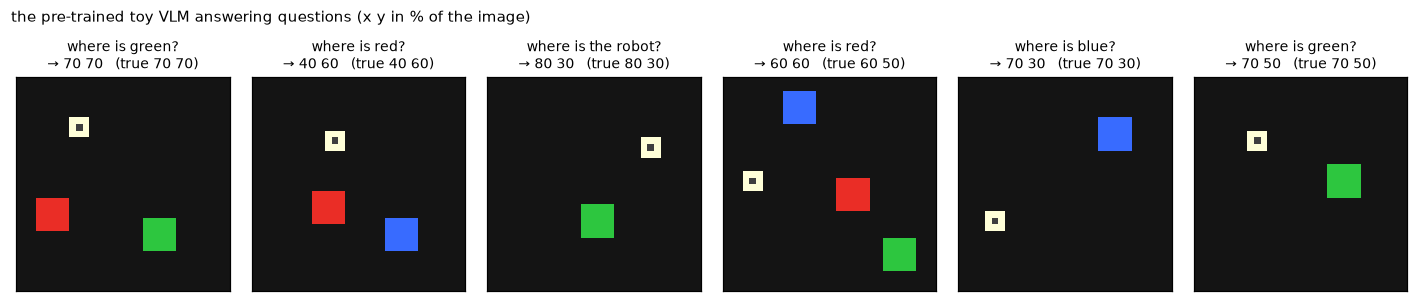

In [12]:
torch.manual_seed(0)
model = Pi0Policy(config)
vqa = VQAPretrainer(model, world)
vqa.fit(1500, log_every=500)
print(f"VQA pre-training took {vqa.history.seconds:.0f} s")
images, questions, answers = vqa.sample(6)
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, img, q, a in zip(axes, images, questions, answers):
    p = vqa.ask(img[None], q)[0]
    plots.show_image(ax, img, f"{q.replace('the object', 'the robot')}?\n→ {p}   (true {a})")
plt.suptitle("the pre-trained toy VLM answering questions (x y in % of the image)", x=0.01, y=1.04, ha="left", fontsize=10)
plt.tight_layout(); plt.show()
pretrained = copy.deepcopy(model)          # snapshot, reused for the baselines in Step 11

## Step 8: Train it on robot data

Loss = flow matching only (π0 has no text loss). Two small tricks for a CPU budget, both standard: several `(ε, τ)` draws per
observation share one backbone pass through the cache (`flow_samples_per_example = 4`), and AdamW with warm-up + cosine decay.

step  1000  loss 0.0539  (flow 0.054, text 0.000)


step  2000  loss 0.0302  (flow 0.030, text 0.000)


step  3000  loss 0.0203  (flow 0.020, text 0.000)
trained in 72 s


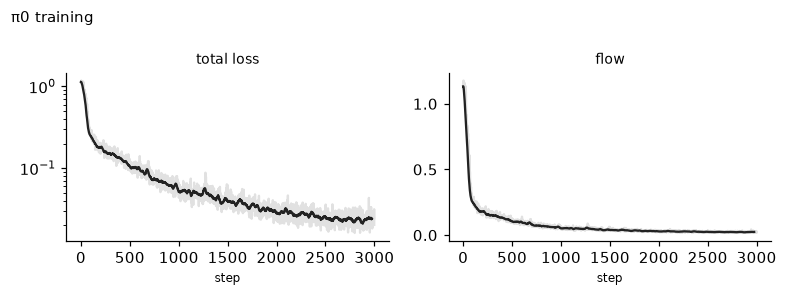

In [13]:
trainer = PiTrainer(model, data, batch_size=64, lr=2e-3)
history = trainer.fit(3000, log_every=3000 // 3)
print(f"trained in {history.seconds:.0f} s")
plots.plot_loss(history, keys=("flow",), title="π0 training")

## Step 9: Watch a chunk being denoised

Each panel is the chunk after *k* of the 10 Euler steps, drawn as the path it would make the robot follow.
It starts as a random scribble and straightens into a reach for the right object. Dots go from red (next action) to yellow (last action of the chunk).

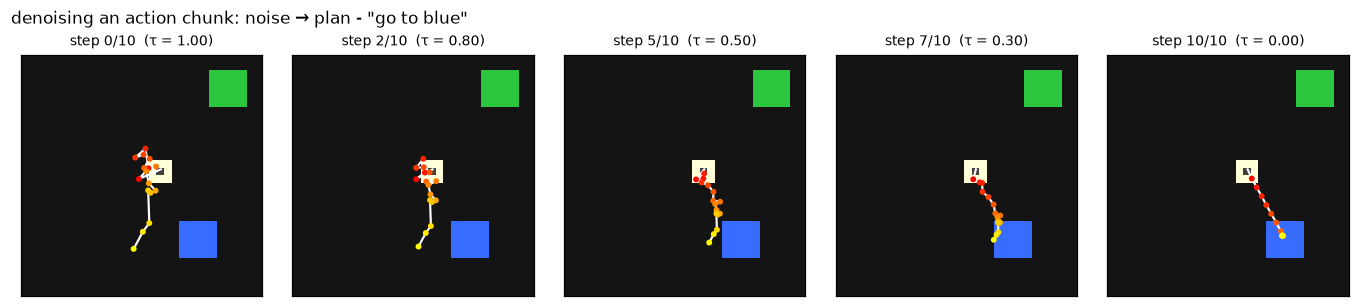

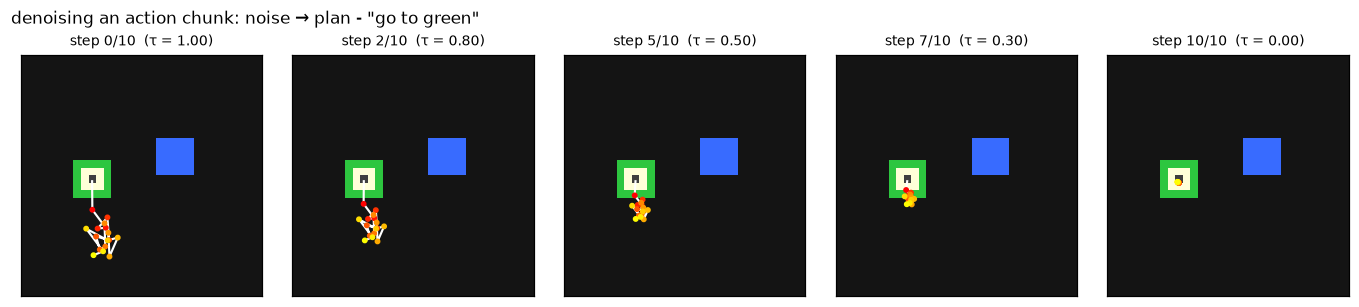

In [14]:
test_data = ChunkDataset(gen.dataset(["reach"], 200, np.random.default_rng(99)), world, config.chunk_size)
tb = test_data.sample(8, np.random.default_rng(3))
_, traj = model.sample_actions(tb, return_trajectory=True)
plots.plot_denoising(tb, traj, example=0)
plots.plot_denoising(tb, traj, example=1)

## Step 10: Closed loop

Now the real test: the robot starts somewhere new, π0 predicts a chunk, the first 8 actions are executed, and it re-plans from the new
image. 64 unseen scenes; success = touching the instructed object within 40 steps.

reach: {'success': 1.0, 'wrong_first': 0.0, 'steps': 11.2, 'path': 0.482}


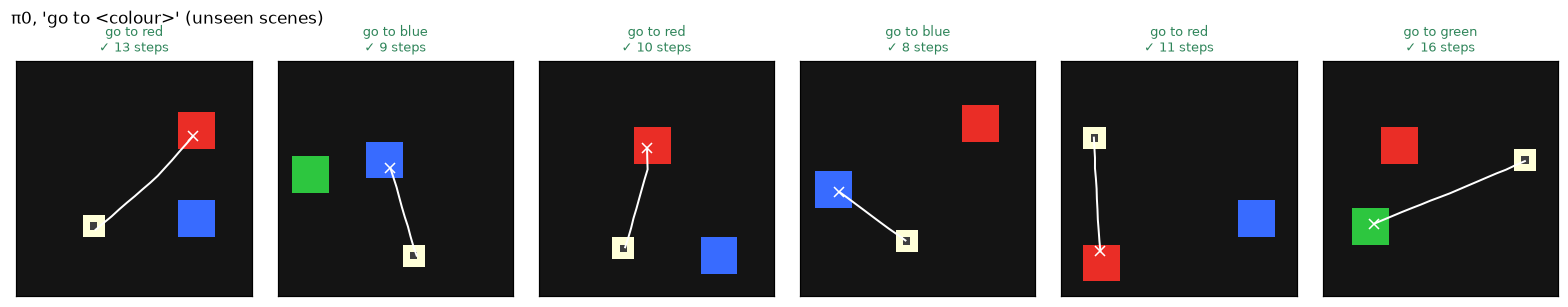

In [15]:
evaluator = ClosedLoopEvaluator(world, config.chunk_size, exec_horizon=8, max_steps=40)
reach = make_scenarios(gen, "reach", 64, seed=123)
r_reach = evaluator.run(lambda b, committed: model.sample_actions(b), reach)
print("reach:", r_reach.summary())
plots.plot_rollouts(r_reach, reach, world, title="π0, 'go to <colour>' (unseen scenes)")

## Step 11: Why flow matching? A multimodal task

For `"go to any"` the demonstrations go to either object with 50 % probability. A regression head trained with L2 learns the **mean** of the
two chunks: a path to the empty space *between* the objects. Flow matching learns the *distribution*: each noise sample commits to one object.

We train two small models on `"go to any"` demonstrations only: π0 (flow matching) and the same architecture with
`action_objective="regression"` (one forward pass, L2 loss), both starting from the same pre-trained VLM snapshot.

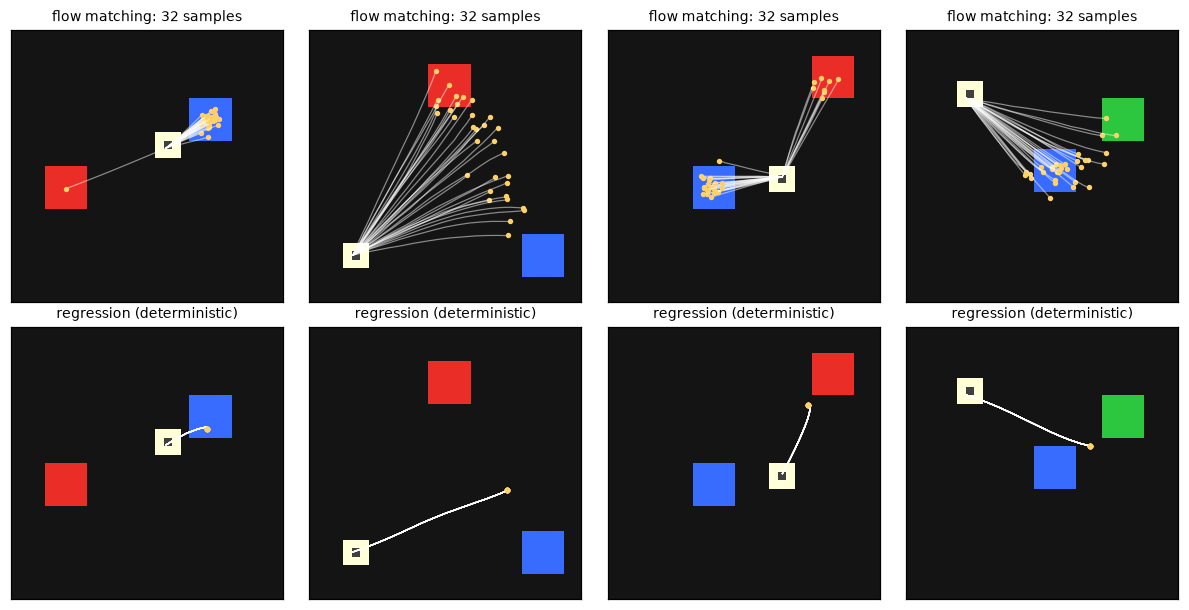

In [16]:
any_data = ChunkDataset(gen.dataset(["any"], 3000, np.random.default_rng(1)), world, config.chunk_size)
torch.manual_seed(0)
flow_any = copy.deepcopy(pretrained)
PiTrainer(flow_any, any_data, batch_size=64, lr=2e-3).fit(4000)
torch.manual_seed(0)
reg_any = Pi0Policy(Pi0Config(action_objective="regression"))
reg_any.load_state_dict(pretrained.state_dict())                 # same weights, different objective
PiTrainer(reg_any, any_data, batch_size=64, lr=2e-3).fit(4000)

any_batch = ChunkDataset(gen.dataset(["any"], 50, np.random.default_rng(7)), world, config.chunk_size).sample(4, np.random.default_rng(8))
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6), facecolor="white")
for i in range(4):
    one = any_batch.replace(images=any_batch.images[i:i + 1].repeat(32, 1, 1, 1), state=any_batch.state[i:i + 1].repeat(32, 1),
                            task=[any_batch.task[i]] * 32)
    plots.plot_samples(one, flow_any.sample_actions(one), example=0, title="flow matching: 32 samples", ax=axes[0, i])
    plots.plot_samples(one, reg_any.sample_actions(one), example=0, title="regression (deterministic)", ax=axes[1, i])
plt.tight_layout(); plt.show()

**How to measure it.** Closed-loop success is a poor judge here: a regression policy that aims between the objects drifts, re-plans from
the new image, and often ends up at one of them anyway. The failure shows in the **chunk itself**. For 100 unseen scenes we take the net
direction of the predicted chunk (one chunk from regression, one *random sample* from flow matching) and ask: is it aimed at an object
(within 15°)? A mean of two good directions is aimed at neither.

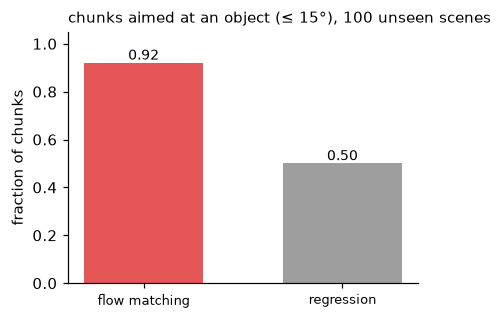

closed-loop success, flow matching: {'success': 0.969, 'wrong_first': 0.0, 'steps': 11.6, 'path': 0.453}
closed-loop success, regression   : {'success': 0.719, 'wrong_first': 0.0, 'steps': 16.5, 'path': 0.514}


In [17]:
def aimed_at_object(model, scenarios, tolerance_deg=15.0):
    s0 = [sc.scene.robot for sc in scenarios]
    imgs = torch.from_numpy(np.stack([world.render(sc.scene.robot, sc.scene.objects) for sc in scenarios]))
    b = collate([dict(image=imgs[i].numpy(), state=s0[i], actions=np.zeros((config.chunk_size, 2), np.float32),
                      history=[imgs[i].numpy()], history_valid=[True], state_history=[s0[i]], subgoal=imgs[i].numpy(),
                      task="go to any", subtask="go to any", metadata=EpisodeMetadata(), control_mode="ee") for i in range(len(scenarios))])
    chunk = model.sample_actions(b)
    hits = []
    for i, sc in enumerate(scenarios):
        net = chunk[i].sum(0).numpy()
        angles = [np.degrees(np.arccos(np.clip(net @ (xy - s0[i]) / (np.linalg.norm(net) * np.linalg.norm(xy - s0[i]) + 1e-9), -1, 1)))
                  for xy in sc.scene.objects.values()]
        hits.append(min(angles) <= tolerance_deg)
    return float(np.mean(hits))

anyt = make_scenarios(gen, "any", 100, seed=321)
aim_flow, aim_reg = aimed_at_object(flow_any, anyt), aimed_at_object(reg_any, anyt)
plots.bar_compare({"flow matching": aim_flow, "regression": aim_reg}, "fraction of chunks", "chunks aimed at an object (≤ 15°), 100 unseen scenes",
                  ylim=(0, 1.05), colors=["#e45756", "#9e9e9e"])
r_any = evaluator.run(lambda b, c: flow_any.sample_actions(b), anyt[:64])
r_any_reg = evaluator.run(lambda b, c: reg_any.sample_actions(b), anyt[:64])
print("closed-loop success, flow matching:", r_any.summary())
print("closed-loop success, regression   :", r_any_reg.summary())

The chunk-level bar is the real comparison. The closed-loop numbers just above are a reminder that re-planning every 8 steps hides much of the
damage in this tiny world, and that our small flow model is a little diffuse (it was trained for 2000 steps on one task); at real scale π0
generates 50-step chunks that must stay committed to one strategy for a full second, which is where averaging hurts.

### Does it really read the instruction and the image? 🔬

Two controls on the `reach` scenes, with the trained flow model:

* **swap the colour word** (`"go to red"` → `"go to blue"`): a model that grounds language must now go to the *other* object, and success is
  measured against the new instruction;
* **black image**: without vision the target is unknowable, success should collapse.

And the number of Euler steps: π0 uses 10; how many does this toy need?

original instruction : 1.00
swapped colour word  : 1.00   (goes to the newly named object)
black image          : 0.00


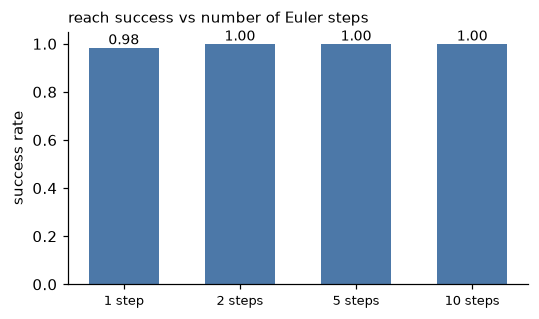

In [18]:
swapped = []
for s in reach:
    other = [c for c in s.scene.objects if c != s.targets[0]][0]
    s2 = copy.copy(s); s2.task, s2.targets, s2.alternatives = f"go to {other}", [other], [other]
    swapped.append(s2)
r_swap = evaluator.run(lambda b, c: model.sample_actions(b), swapped)
r_blind = evaluator.run(lambda b, c: model.sample_actions(b.replace(images=torch.zeros_like(b.images))), reach)
print(f"original instruction : {r_reach.success_rate:.2f}")
print(f"swapped colour word  : {r_swap.success_rate:.2f}   (goes to the newly named object)")
print(f"black image          : {r_blind.success_rate:.2f}")
steps = {f"{k} step{'s' * (k > 1)}": evaluator.run(lambda b, c, k=k: model.sample_actions(b, num_steps=k), reach).success_rate
         for k in (1, 2, 5, 10)}
plots.bar_compare(steps, "success rate", "reach success vs number of Euler steps", ylim=(0, 1.05))

## Step 12: Recap and exercises

```
image ─► patch tokens ┐                                     (VLM weights, run once, KV-cached)
text  ─► word tokens  ┴─► [prefix block] ──────────────────────────────────┐ keys/values
state ─► linear ─────────► [state block]  ┐                                ▼
noise ε, τ ─► action-time MLP ─► [action block] ─► action expert ─► v_θ ─► Euler × 10 ─► chunk a_t..a_t+H-1
loss:  ‖ v_θ(τε + (1-τ)a, τ | o) − (ε − a) ‖²,   τ ~ 0.999·Beta(1.5, 1) + 0.001
```

**What π0 got right:** continuous, high-frequency, multimodal actions from a VLM, with only a small expert running per denoising step.
**What it left open** (and π0.5 addresses): the VLM's knowledge degrades when flow-matching gradients from a randomly initialised expert
flow into it; the prompt is a single short instruction; long tasks need the model to decide *what to do next*.

### 🧪 Exercises
1. Set `time_beta_a=1.0` (uniform τ) and retrain. Does reach or "any" change?
2. Give the state block `ar = False` (merge it into the action block) in `Pi0Policy.build_suffix`. Is the cached result still exact? (It should be: the prefix is unaffected.)
3. Train with `expert_output_norm=True` (the published design) for the same number of steps and compare success; read the comment in `Pi0Config` for why it matters at width 48.
4. Skip Stage 0 (no VQA pre-training) and train on robot data for the same number of steps. How does success change? Why is the
   flow-matching gradient alone a poor teacher for the backbone? (This is also the motivation for π0.5's knowledge insulation.)
5. Replace the `"go to any"` scenes by three objects. How do the flow samples split?